In [ ]:
# ============================================================
# Simulation Study: Wasserstein Target Diagram
# Unequal Sample Sizes — Exact Empirical Quantile Integration
# ============================================================

import numpy as np
import pandas as pd
from scipy import stats
from pathlib import Path

np.random.seed(123)


# --------------------------------------------------
# Observed data: Gamma(shape=4, scale=1)
# Theoretical mean = 4, standard deviation = 2
# --------------------------------------------------

obs = np.random.gamma(shape=4, scale=1, size=10000)

std_obs = np.std(obs, ddof=0)
mean_obs = np.mean(obs)


# --------------------------------------------------
# Prediction distributions
# --------------------------------------------------

predictions = {
    "Pred 1: GAM(4,1), n=20000":
        np.random.gamma(shape=4, scale=1, size=20000),

    "Pred 2: GAM(4,0.8), n=15000":
        np.random.gamma(shape=4, scale=0.8, size=15000),

    "Pred 3: GAM(4,1.2), n=25000":
        np.random.gamma(shape=4, scale=1.2, size=25000),

    "Pred 4: GAM(9,0.5), n=18000":
        np.random.gamma(shape=9, scale=0.5, size=18000),

    "Pred 5: GAM(4,1)+1, n=22000":
        np.random.gamma(shape=4, scale=1, size=22000) + 1,

    "Pred 6: W(2,4.5), n=30000":
        stats.weibull_min.rvs(c=2, scale=4.5, size=30000),

    "Pred 7: LogN(1.285,0.2025), n=25000":
        np.random.lognormal(mean=1.285, sigma=0.45, size=25000),

    "Pred 8: N(4,4), n=35000":
        np.random.normal(loc=4, scale=2, size=35000),

    "Pred 9: Bimodal, n=40000":
        np.concatenate([
            np.random.normal(loc=2.5, scale=0.5, size=20000),
            np.random.normal(loc=5.5, scale=0.5, size=20000)
        ])
}


# --------------------------------------------------
# Clean and sort samples
# --------------------------------------------------

def clean_sorted(data):
    data = np.asarray(data, dtype=float).ravel()
    data = data[~np.isnan(data)]
    return np.sort(data)


# --------------------------------------------------
# Equation (2.4):  get 2-Wasserstein distance
# --------------------------------------------------

def empirical_wasserstein_statistics(x, y):
    x = clean_sorted(x)
    y = clean_sorted(y)

    M, N = len(x), len(y)

    mean_x = np.mean(x)
    mean_y = np.mean(y)
    std_x = np.std(x, ddof=0)
    std_y = np.std(y, ddof=0)

    x_centered = x - mean_x
    y_centered = y - mean_y

    w2_squared = 0.0
    centered_w2_squared = 0.0

    i = 1
    j = 1

    while i <= M and j <= N:
        # Your formula:
        # w_ij = [min(i/M, j/N)
        #         - max((i-1)/M, (j-1)/N)]_+
        w_ij = max(
            min(i / M, j / N)
            - max((i - 1) / M, (j - 1) / N),
            0.0
        )

        # Equation (2.4)
        w2_squared += w_ij * (x[i - 1] - y[j - 1])**2

        centered_w2_squared += w_ij * (
            x_centered[i - 1] - y_centered[j - 1]
        )**2

        # Advance the interval that ends first.
        # Save endpoints before updating either index.
        right_x = i / M
        right_y = j / N

        if right_x <= right_y:
            i += 1
        if right_y <= right_x:
            j += 1

    w2_centered = np.sqrt(centered_w2_squared)

    return {
        "prediction_std": std_y,
        "ground_truth_std": std_x,
        "Centered_W_2": w2_centered,
        "Signed_Centered_W_2": (
            np.sign(std_y - std_x) * w2_centered
        ),
        "prediction_mean": mean_y,
        "ground_truth_mean": mean_x,
        "Bias": mean_y - mean_x,
        "W_2": np.sqrt(w2_squared)
    }



# --------------------------------------------------
# Compute quantities for all predictions
# --------------------------------------------------

rows = []

for name, pred in predictions.items():
    quantities = empirical_wasserstein_statistics(obs, pred)

    # Check the bias–centered-distance decomposition
    lhs = quantities["W_2"]**2
    rhs = quantities["Centered_W_2"]**2 + quantities["Bias"]**2

    print(f"Model: {name}")
    print(f"W2 squared                  = {lhs:.15f}")
    print(f"Centered W2 squared + Bias² = {rhs:.15f}")
    print(f"Absolute error              = {abs(lhs - rhs):.3e}")

    np.testing.assert_allclose(
        lhs, rhs,
        rtol=1e-10,
        atol=1e-12
    )

    print("Decomposition check passed.\n")

    rows.append({
        "Model": name.split(": ", 1)[1],
        **quantities
    })

results = pd.DataFrame(rows)


# --------------------------------------------------
# Save results
# --------------------------------------------------

# Use the Colab sample_data folder when available;
# otherwise save in the current working directory.
output_dir = Path("/content/sample_data")
if not output_dir.is_dir():
    output_dir = Path.cwd()

output_path = (
    output_dir / "Simulation_Wasserstein_Target_Diagram.csv"
)
results.to_csv(output_path, index=False)


# --------------------------------------------------
# Print results
# --------------------------------------------------

print(f"Observed length = {len(obs)}")
print(f"Observed mean   = {mean_obs:.6f}")
print(f"Observed std    = {std_obs:.6f}")

print(results.to_string(
    index=False,
    float_format=lambda value: f"{value:.6f}"
))

print(f"\nResults saved to: {output_path}")

Model: Pred 1: GAM(4,1), n=20000
W2 squared                  = 0.003407056436552
Centered W2 squared + Bias² = 0.003407056436552
Absolute error              = 8.327e-17
Decomposition check passed.

Model: Pred 2: GAM(4,0.8), n=15000
W2 squared                  = 0.835295985561088
Centered W2 squared + Bias² = 0.835295985561088
Absolute error              = 7.772e-16
Decomposition check passed.

Model: Pred 3: GAM(4,1.2), n=25000
W2 squared                  = 0.681761816575650
Centered W2 squared + Bias² = 0.681761816575649
Absolute error              = 4.441e-16
Decomposition check passed.

Model: Pred 4: GAM(9,0.5), n=18000
W2 squared                  = 0.514570609324596
Centered W2 squared + Bias² = 0.514570609324598
Absolute error              = 1.665e-15
Decomposition check passed.

Model: Pred 5: GAM(4,1)+1, n=22000
W2 squared                  = 0.998428374237482
Centered W2 squared + Bias² = 0.998428374237478
Absolute error              = 4.552e-15
Decomposition check passed.

Mo

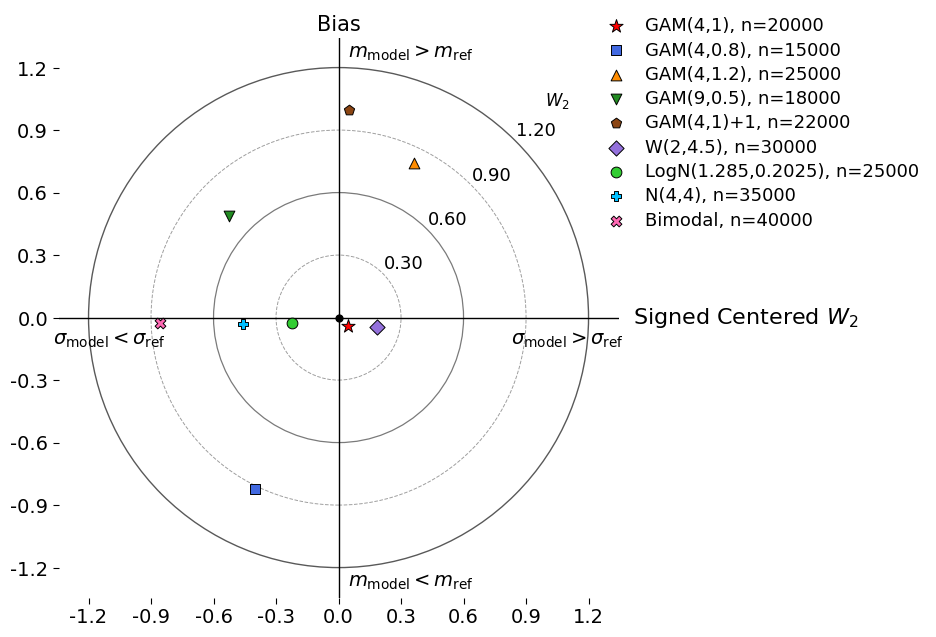

Figure saved to: /content/sample_data/Simulation_Unequal_Length_Wasserstein_Target_Diagram.pdf


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

# ============================================================
# Wasserstein Target Diagram: Simulation Study
# Uses the results DataFrame from the preceding calculation
# ============================================================

fig, ax = plt.subplots(figsize=(8, 8))


# ------------------------------------------------------------
# Determine outer W2 radius
# ------------------------------------------------------------

max_w2 = results["W_2"].max()

if max_w2 <= 0.1:
    outer_step = 0.05
elif max_w2 <= 0.2:
    outer_step = 0.10
elif max_w2 <= 0.5:
    outer_step = 0.20
elif max_w2 <= 1.0:
    outer_step = 0.40
elif max_w2 <= 2.0:
    outer_step = 0.80
elif max_w2 <= 5.0:
    outer_step = 2.0
else:
    outer_step = 4.0

rmax = max(outer_step, np.ceil(max_w2 / outer_step) * outer_step)

# Exactly four equally spaced circles
radii = np.linspace(rmax / 4, rmax, 4)


# ------------------------------------------------------------
# Draw four W2 circles
# ------------------------------------------------------------

circle_styles = [
    ("--", 0.7, 0.38),
    ("-", 0.9, 0.52),
    ("--", 0.7, 0.38),
    ("-", 1.0, 0.65)
]

for r, (linestyle, linewidth, alpha) in zip(radii, circle_styles):
    ax.add_patch(
        plt.Circle(
            (0, 0),
            r,
            fill=False,
            edgecolor="black",
            linewidth=linewidth,
            linestyle=linestyle,
            alpha=alpha,
            zorder=0
        )
    )


# ------------------------------------------------------------
# Label W2 contours
# ------------------------------------------------------------

theta = np.pi / 4

for r in radii:
    ax.text(
        (r + 0.005 * rmax) * np.cos(theta),
        (r + 0.005 * rmax) * np.sin(theta),
        f"{r:.2f}",
        fontsize=13,
        color="black",
        ha="left",
        va="bottom"
    )

ax.text(
    (rmax * 1.17) * np.cos(theta),
    (rmax * 1.17) * np.sin(theta),
    r"$W_2$",
    fontsize=12,
    color="black",
    ha="left",
    va="bottom"
)


# ------------------------------------------------------------
# Model colors and markers
# ------------------------------------------------------------

model_colors = {
    "GAM(4,1), n=20000": "red",
    "GAM(4,0.8), n=15000": "royalblue",
    "GAM(4,1.2), n=25000": "darkorange",
    "GAM(9,0.5), n=18000": "forestgreen",
    "GAM(4,1)+1, n=22000": "saddlebrown",
    "W(2,4.5), n=30000": "mediumpurple",
    "LogN(1.285,0.2025), n=25000": "limegreen",
    "N(4,4), n=35000": "deepskyblue",
    "Bimodal, n=40000": "hotpink"
}

model_markers = {
    "GAM(4,1), n=20000": "*",
    "GAM(4,0.8), n=15000": "s",
    "GAM(4,1.2), n=25000": "^",
    "GAM(9,0.5), n=18000": "v",
    "GAM(4,1)+1, n=22000": "p",
    "W(2,4.5), n=30000": "D",
    "LogN(1.285,0.2025), n=25000": "o",
    "N(4,4), n=35000": "P",
    "Bimodal, n=40000": "X"
}


# ------------------------------------------------------------
# Plot models directly from results
# ------------------------------------------------------------

for _, row in results.iterrows():
    name = row["Model"]
    x = row["Signed_Centered_W_2"]
    y = row["Bias"]

    size = 100 if name == "GAM(4,1), n=20000" else 60

    ax.scatter(
        x,
        y,
        s=size,
        marker=model_markers[name],
        facecolor=model_colors[name],
        edgecolor="black",
        linewidth=0.7,
        label=name,
        zorder=3
    )


# ------------------------------------------------------------
# Reference axes and origin
# ------------------------------------------------------------

ax.axhline(0, color="black", linewidth=1.0, zorder=1)
ax.axvline(0, color="black", linewidth=1.0, zorder=1)

ax.scatter(0, 0, s=24, color="black", zorder=4)


# ------------------------------------------------------------
# Axis limits and aspect ratio
# ------------------------------------------------------------

limit = rmax * 1.12

ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)
ax.set_aspect("equal", adjustable="box")

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xlabel("")
ax.set_ylabel("")


# ------------------------------------------------------------
# Coordinate titles
# ------------------------------------------------------------

ax.text(
    limit * 1.05,
    0,
    r"Signed Centered $W_2$",
    fontsize=16,
    ha="left",
    va="center",
    clip_on=False
)

ax.text(
    0,
    limit * 1.01,
    "Bias",
    fontsize=15,
    ha="center",
    va="bottom",
    clip_on=False
)


# ------------------------------------------------------------
# Interpretation of coordinate signs
# ------------------------------------------------------------

ax.text(
    -limit * 1.02,
    -0.045 * limit,
    r"$\sigma_{\mathrm{model}}<\sigma_{\mathrm{ref}}$",
    fontsize=14,
    color="black",
    ha="left",
    va="top"
)

ax.text(
    limit * 1.02,
    -0.045 * limit,
    r"$\sigma_{\mathrm{model}}>\sigma_{\mathrm{ref}}$",
    fontsize=14,
    color="black",
    ha="right",
    va="top"
)

ax.text(
    0.035 * limit,
    limit * 0.98,
    r"$m_{\mathrm{model}}>m_{\mathrm{ref}}$",
    fontsize=14,
    color="black",
    ha="left",
    va="top"
)

ax.text(
    0.035 * limit,
    -limit * 0.98,
    r"$m_{\mathrm{model}}<m_{\mathrm{ref}}$",
    fontsize=14,
    color="black",
    ha="left",
    va="bottom"
)


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

ax.legend(
    frameon=False,
    fontsize=13,
    loc="upper left",
    bbox_to_anchor=(0.95, 1.05),
    handletextpad=0.6,
    labelspacing=0.35,
    borderaxespad=0
)


# ------------------------------------------------------------
# Tick locations and formatting
# ------------------------------------------------------------

ticks = np.linspace(-rmax, rmax, 9)

ax.set_xticks(ticks)
ax.set_yticks(ticks)

if rmax < 1:
    tick_format = "%.2f"
elif rmax < 10:
    tick_format = "%.1f"
else:
    tick_format = "%.0f"

ax.xaxis.set_major_formatter(FormatStrFormatter(tick_format))
ax.yaxis.set_major_formatter(FormatStrFormatter(tick_format))

ax.tick_params(direction="out", labelsize=14, length=4)


# ------------------------------------------------------------
# Layout and saving
# output_dir was defined in the preceding simulation code
# ------------------------------------------------------------

plt.subplots_adjust(
    left=0.08,
    right=0.78,
    bottom=0.08,
    top=0.97
)

figure_path = (
    output_dir
    / "Simulation_Unequal_Length_Wasserstein_Target_Diagram.pdf"
)

fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Figure saved to: {figure_path}")